# Practice 06 — Unsupervised Learning

**Goal:** find structure in `X` alone — no label is used for fitting.

| Family | Question | Methods |
|:---|:---|:---|
| Clustering | which samples belong together? | Hierarchical, K-means, DBSCAN |
| Dimensionality reduction | can the features be compressed? | PCA, t-SNE |

- Iris labels → set aside as `y_true`, used only to check the result afterwards

---
## Step 0. Imports

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'   # must be set before sklearn is imported

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

from sklearn.datasets import load_iris, make_moons
from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score

np.random.seed(42)
plt.rcParams['axes.unicode_minus'] = False

---
## Step 1. Data — Features Only

- No train/test split → clustering only describes the given set
- All four features are lengths in **cm** → used as measured
- Features in different units → standardize first, or the feature with the largest numbers dominates every distance

In [2]:
iris = load_iris()

X      = iris.data          # the features the algorithms will see
y_true = iris.target        # set aside - used only to check the result

print(f'X: {X.shape}')
display(pd.DataFrame(X, columns=iris.feature_names).head(10))

X: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
5,5.4,3.9,1.7,0.4
6,4.6,3.4,1.4,0.3
7,5.0,3.4,1.5,0.2
8,4.4,2.9,1.4,0.2
9,4.9,3.1,1.5,0.1


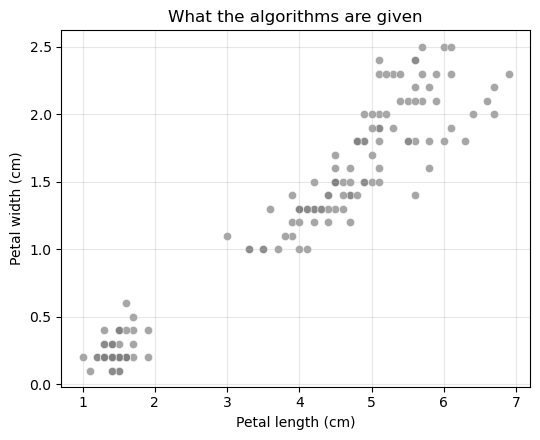

In [3]:
plt.figure(figsize=(5.5, 4.5))
plt.scatter(X[:, 2], X[:, 3], c='gray', s=35, alpha=0.7, edgecolors='white', linewidths=0.5)
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('What the algorithms are given')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Two groups are obvious → is the upper-right one a single group or two?
- Plots below use these two axes → the algorithms still use all four features

---
## Step 2. Hierarchical Clustering

- Each sample starts as its own cluster → merge the two closest → repeat
- Merge history = **dendrogram** → cut it at a height, and the number of clusters follows

| `method` | Distance between two clusters |
|:---|:---|
| `single` | closest pair of points |
| `complete` | farthest pair |
| `average` | average over all pairs |
| `centroid` | between the two centroids |
| `ward` | increase in within-cluster sum of squares |

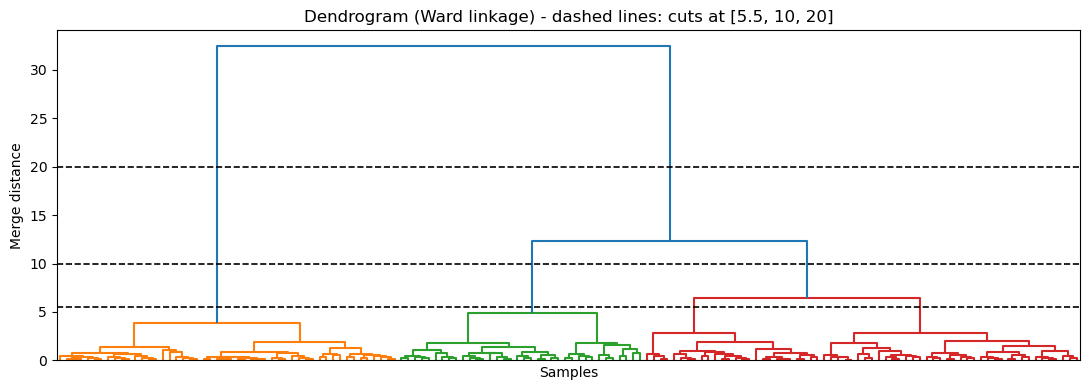

In [4]:
linkage_matrix = linkage(X, method='ward')

cut_heights = [5.5, 10, 20]

plt.figure(figsize=(11, 4))
dendrogram(linkage_matrix, no_labels=True, color_threshold=10)
for height in cut_heights:
    plt.axhline(height, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Samples')
plt.ylabel('Merge distance')
plt.title(f'Dendrogram (Ward linkage) - dashed lines: cuts at {cut_heights}')
plt.tight_layout()
plt.show()

- Clusters at a cut = vertical lines the cut crosses → lower cut, more clusters
- `fcluster` → cut at a height; `AgglomerativeClustering` → ask for a number of clusters

cut at 5.5 -> 4 clusters, sizes [50 36 26 38]
cut at 10 -> 3 clusters, sizes [50 36 64]
cut at 20 -> 2 clusters, sizes [ 50 100]


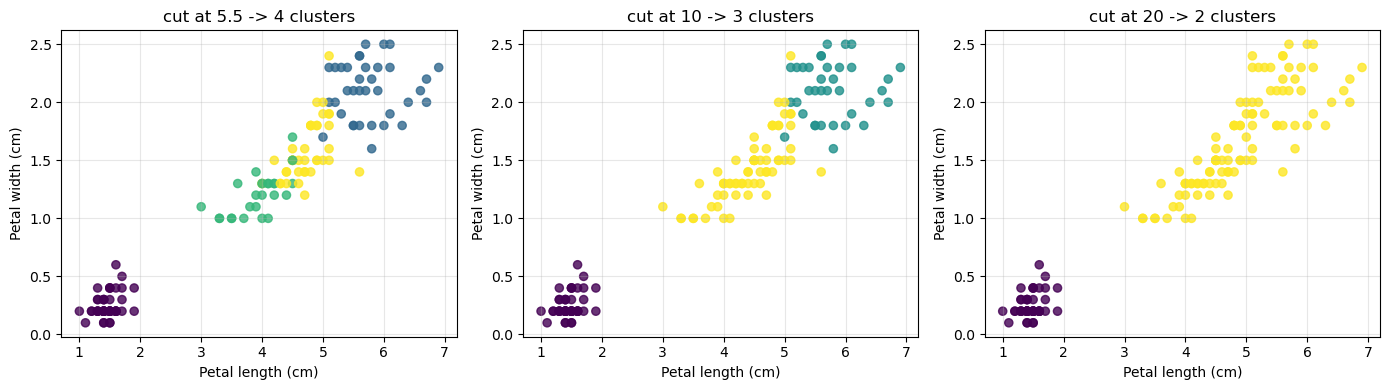

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, height in zip(axes, cut_heights):
    labels_at_height = fcluster(linkage_matrix, height, criterion='distance')   # cut the tree at this height
    n_clusters = labels_at_height.max()                                         # fcluster numbers clusters 1, 2, ...
    print(f'cut at {height} -> {n_clusters} clusters, sizes {np.bincount(labels_at_height)[1:]}')

    ax.scatter(X[:, 2], X[:, 3], c=labels_at_height, cmap='viridis', s=35, alpha=0.8)
    ax.set_xlabel('Petal length (cm)'); ax.set_ylabel('Petal width (cm)')
    ax.set_title(f'cut at {height} -> {n_clusters} clusters')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
hierarchical = AgglomerativeClustering(n_clusters=3, linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X)

print(f'AgglomerativeClustering(n_clusters=3) -> sizes {np.bincount(hierarchical_labels)}')

AgglomerativeClustering(n_clusters=3) -> sizes [64 50 36]


- `AgglomerativeClustering(n_clusters=3)` → the same three groups as the cut at 10; only the label numbers differ

---
## Step 3. K-means, and Choosing $k$

- Place $k$ centres → assign each point to the nearest → move each centre to the mean of its points → repeat
- `n_init=10` → ten random starts, the best one is kept

### Choosing $k$

| Index | Definition | How to read it |
|:---|:---|:---|
| Inertia (WSS) | $\sum_{j=1}^{k}\sum_{\mathbf{x} \in C_j} \lVert \mathbf{x} - \boldsymbol{\mu}_j \rVert^2$ | always falls as $k$ grows → look for the **elbow** |
| Silhouette | mean over samples of $\dfrac{b - a}{\max(a, b)} \in [-1, 1]$ | higher = tighter and better separated → take the **maximum** |

- $a$ = mean distance to the own cluster, $b$ = to the nearest other cluster

k = 1   inertia =  681.4   silhouette = nan
k = 2   inertia =  152.3   silhouette = 0.6810
k = 3   inertia =   78.9   silhouette = 0.5528
k = 4   inertia =   57.2   silhouette = 0.4981
k = 5   inertia =   46.5   silhouette = 0.4912
k = 6   inertia =   39.0   silhouette = 0.3648
k = 7   inertia =   34.3   silhouette = 0.3543
k = 8   inertia =   30.1   silhouette = 0.3487
k = 9   inertia =   28.3   silhouette = 0.3125


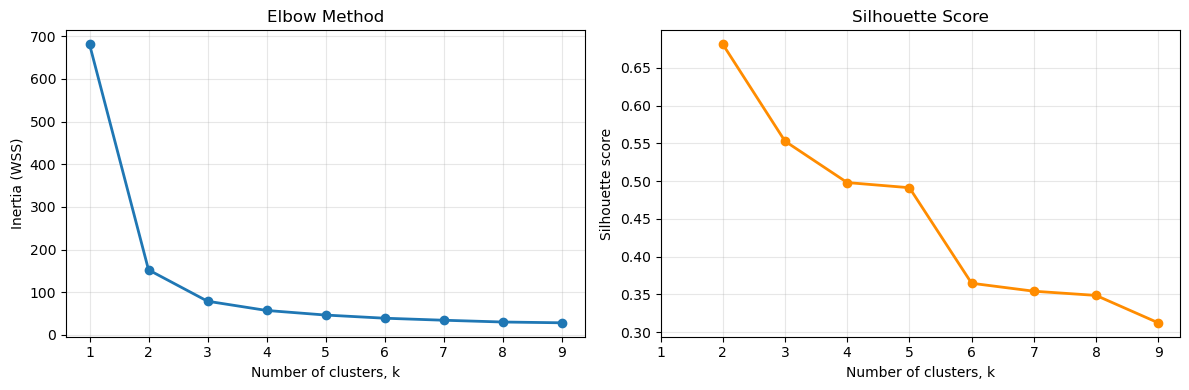

In [7]:
k_values = range(1, 10)
inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)
    if k == 1:
        silhouette_values.append(np.nan)      # the silhouette needs at least two clusters
    else:
        silhouette_values.append(silhouette_score(X, kmeans.labels_))
    print(f'k = {k}   inertia = {inertia_values[-1]:6.1f}   silhouette = {silhouette_values[-1]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertia_values, 'o-', linewidth=2)
axes[0].set_xlabel('Number of clusters, k'); axes[0].set_ylabel('Inertia (WSS)')
axes[0].set_title('Elbow Method'); axes[0].set_xticks(list(k_values)); axes[0].grid(alpha=0.3)

axes[1].plot(list(k_values), silhouette_values, 'o-', linewidth=2, color='darkorange')
axes[1].set_xlabel('Number of clusters, k'); axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette Score'); axes[1].set_xticks(list(k_values)); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Elbow → sharpest bend at $k = 2$, a smaller one at $k = 3$, flat after that
- Silhouette → highest at $k = 2$: the upper-right group has no gap, so splitting it lowers the score
- $k = 3$ is used below → the last $k$ with a visible bend

cluster sizes: [62 50 38]
inertia      : 78.85


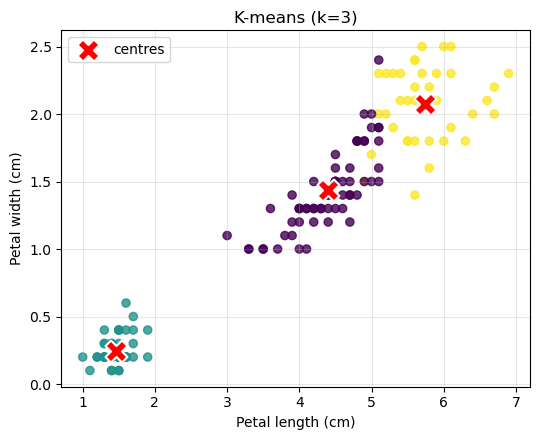

In [8]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

print(f'cluster sizes: {np.bincount(kmeans_labels)}')
print(f'inertia      : {kmeans.inertia_:.2f}')

plt.figure(figsize=(5.5, 4.5))
plt.scatter(X[:, 2], X[:, 3], c=kmeans_labels, cmap='viridis', s=35, alpha=0.8)
plt.scatter(centers[:, 2], centers[:, 3], c='red', marker='X', s=250, edgecolors='white', linewidths=1.5, label='centres')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('K-means (k=3)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Step 4. DBSCAN

- Cluster = dense region → a point in no dense region is **noise**, label `-1`
- No $k$ → the number of clusters follows from the two parameters

| Parameter | Meaning |
|:---|:---|
| `eps` | radius of the neighbourhood around a point |
| `min_samples` | points needed inside it to make a *core point* |

In [9]:
for eps in [0.3, 0.5, 0.8]:
    dbscan = DBSCAN(eps=eps, min_samples=5)
    labels_at_eps = dbscan.fit_predict(X)
    n_clusters = labels_at_eps.max() + 1             # clusters are numbered 0, 1, ...; noise is -1
    n_noise = (labels_at_eps == -1).sum()
    print(f'eps = {eps:.1f} -> {n_clusters} clusters, {n_noise:2d} noise points')

eps = 0.3 -> 3 clusters, 96 noise points
eps = 0.5 -> 2 clusters, 17 noise points
eps = 0.8 -> 2 clusters,  2 noise points


cluster sizes: [49 84]
noise points : 17


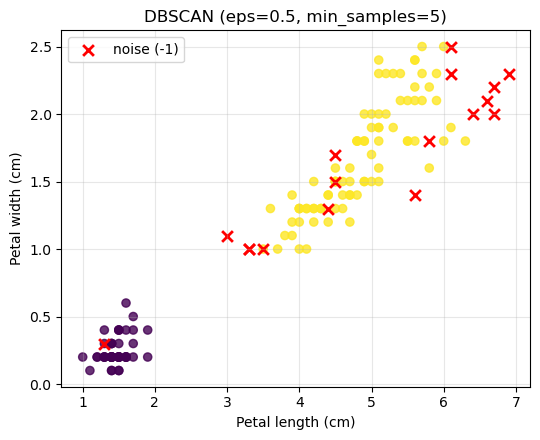

In [10]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)

is_noise = dbscan_labels == -1
print(f'cluster sizes: {np.bincount(dbscan_labels[~is_noise])}')
print(f'noise points : {is_noise.sum()}')

plt.figure(figsize=(5.5, 4.5))
plt.scatter(X[~is_noise, 2], X[~is_noise, 3], c=dbscan_labels[~is_noise], cmap='viridis', s=35, alpha=0.8)
plt.scatter(X[is_noise, 2], X[is_noise, 3], c='red', marker='x', s=60, linewidths=2, label='noise (-1)')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('DBSCAN (eps=0.5, min_samples=5)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- `eps = 0.3` → most points are noise; `eps = 0.5` and `0.8` → **two** clusters, not three
- The upper-right group is one connected dense region → a density-based method does not split it

---
## Step 5. Evaluating a Clustering

| Kind | Index | Needs labels | Asks |
|:---|:---|:---|:---|
| Internal | silhouette | no | are the clusters tight and far apart? |
| External | Adjusted Rand Index (ARI) | yes | do clustering and truth agree, pair by pair? |

- ARI → 0 = random assignment, 1 = identical; cluster numbering does not matter
- No labels → only the internal index exists

In [11]:
# DBSCAN's noise label -1 is scored as one more cluster, by both indices
rows = [
    {'labels': 'Hierarchical (k=3)', 'silhouette': silhouette_score(X, hierarchical_labels),
     'ARI vs truth': adjusted_rand_score(y_true, hierarchical_labels)},
    {'labels': 'K-means (k=3)',      'silhouette': silhouette_score(X, kmeans_labels),
     'ARI vs truth': adjusted_rand_score(y_true, kmeans_labels)},
    {'labels': 'DBSCAN (eps=0.5)',   'silhouette': silhouette_score(X, dbscan_labels),
     'ARI vs truth': adjusted_rand_score(y_true, dbscan_labels)},
    {'labels': 'the true species',   'silhouette': silhouette_score(X, y_true),
     'ARI vs truth': adjusted_rand_score(y_true, y_true)},
]
display(pd.DataFrame(rows).round(4))

,labels,silhouette,ARI vs truth
0,Hierarchical (k=3),0.5543,0.7312
1,K-means (k=3),0.5528,0.7302
2,DBSCAN (eps=0.5),0.4860,0.5206
3,the true species,0.5035,1.0000


- True species → silhouette 0.50, **below** hierarchical and K-means (0.55): the index rewards compact shape, not correctness
- ARI tells them apart → hierarchical and K-means 0.73, DBSCAN 0.52 (two species merged)

---
## Step 6. When K-means Fails

- K-means assigns each point to the nearest centre → straight boundaries, round clusters
- `make_moons` → two interleaved crescents with known labels, so ARI is available

K-means ARI : 0.2542
DBSCAN  ARI : 1.0000
DBSCAN found 2 clusters, 0 noise points


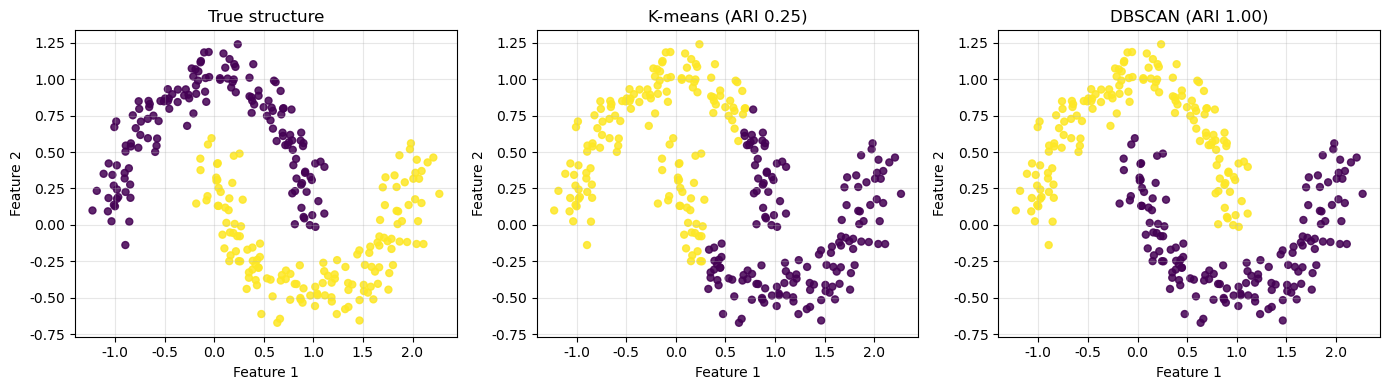

In [12]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.1, random_state=42)

kmeans_moons = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans_labels_moons = kmeans_moons.fit_predict(X_moons)

dbscan_moons = DBSCAN(eps=0.2, min_samples=5)
dbscan_labels_moons = dbscan_moons.fit_predict(X_moons)

ari_kmeans = adjusted_rand_score(y_moons, kmeans_labels_moons)
ari_dbscan = adjusted_rand_score(y_moons, dbscan_labels_moons)

print(f'K-means ARI : {ari_kmeans:.4f}')
print(f'DBSCAN  ARI : {ari_dbscan:.4f}')
print(f'DBSCAN found {dbscan_labels_moons.max() + 1} clusters, {(dbscan_labels_moons == -1).sum()} noise points')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='viridis', s=25, alpha=0.85)
axes[0].set_title('True structure')
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=kmeans_labels_moons, cmap='viridis', s=25, alpha=0.85)
axes[1].set_title(f'K-means (ARI {ari_kmeans:.2f})')
axes[2].scatter(X_moons[:, 0], X_moons[:, 1], c=dbscan_labels_moons, cmap='viridis', s=25, alpha=0.85)
axes[2].set_title(f'DBSCAN (ARI {ari_dbscan:.2f})')

for ax in axes:
    ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2'); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- DBSCAN → each crescent is one connected dense region, so both are recovered exactly
- On Iris DBSCAN was the weaker choice, here K-means is → the data decides

---
## Step 7. PCA

- PC 1 = direction of largest variance, PC 2 = the largest among directions orthogonal to PC 1, and so on
- `explained_variance_ratio_` → fraction of the variance each component carries
- PCA follows variance → the unit rule from Step 1 applies here too

explained variance ratio : [0.9246 0.0531 0.0171 0.0052]
cumulative               : [0.9246 0.9777 0.9948 1.    ]


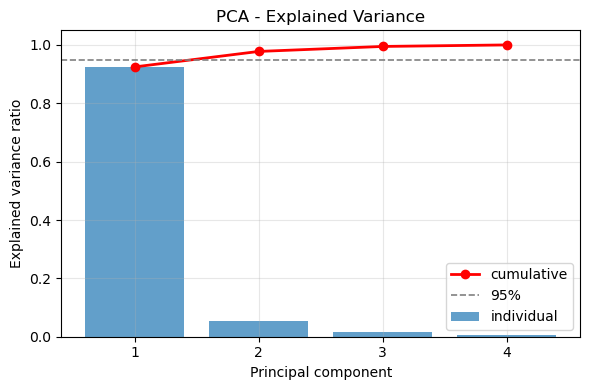

In [13]:
pca_full = PCA()
pca_full.fit(X)
explained = pca_full.explained_variance_ratio_

print('explained variance ratio :', explained.round(4))
print('cumulative               :', explained.cumsum().round(4))

fig, ax = plt.subplots(figsize=(6, 4))
components = range(1, len(explained) + 1)
ax.bar(components, explained, alpha=0.7, label='individual')
ax.plot(components, explained.cumsum(), 'ro-', linewidth=2, label='cumulative')
ax.axhline(0.95, color='gray', linestyle='--', linewidth=1.2, label='95%')
ax.set_xlabel('Principal component'); ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA - Explained Variance'); ax.set_xticks(list(components))
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

X: (150, 4) -> X_pca: (150, 2)


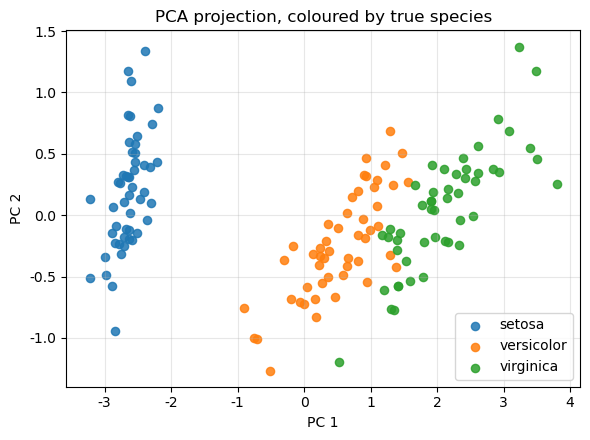

In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print(f'X: {X.shape} -> X_pca: {X_pca.shape}')

# the labels are used for colouring only
plt.figure(figsize=(6, 4.5))
for species in range(3):
    is_species = y_true == species
    plt.scatter(X_pca[is_species, 0], X_pca[is_species, 1], s=35, alpha=0.85, label=iris.target_names[species])
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('PCA projection, coloured by true species')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Two components keep 98% of the variance, above the 95% line → the 2-D plot loses almost nothing
- Setosa is far from the rest; versicolor and virginica are adjacent and overlap by a few samples
- That overlap is in the data, not made by PCA → why no method above found three clean groups

---
## Step 8. t-SNE

- Places the points in 2-D so that neighbours in the original space stay neighbours
- `perplexity` (5 to 50) ≈ how many neighbours count
- Stochastic → fix `random_state`

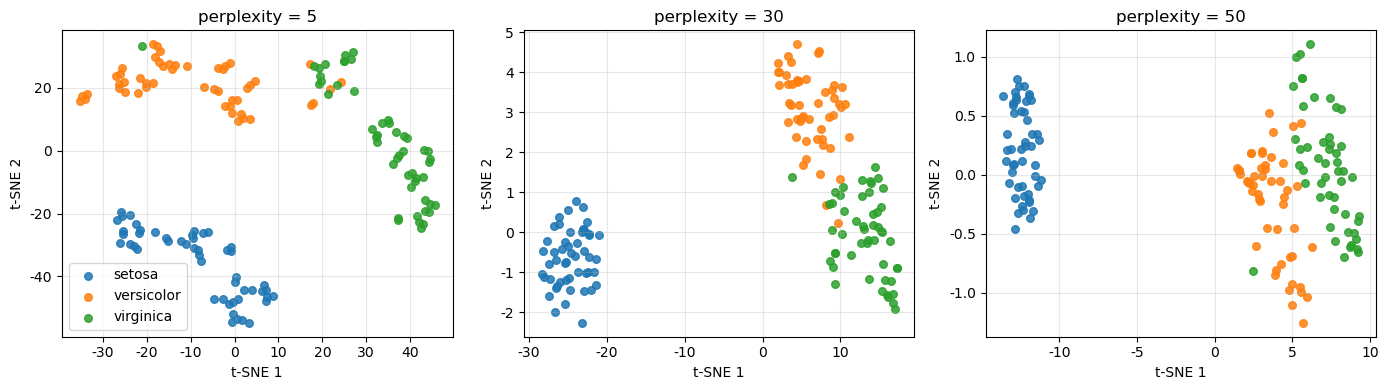

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, perplexity in zip(axes, [5, 30, 50]):
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42, init='pca')
    X_tsne = tsne.fit_transform(X)

    for species in range(3):
        is_species = y_true == species
        ax.scatter(X_tsne[is_species, 0], X_tsne[is_species, 1], s=30, alpha=0.85, label=iris.target_names[species])
    ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
    ax.set_title(f'perplexity = {perplexity}')
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()

- Same structure as PCA at every setting → setosa apart, versicolor and virginica adjacent
- `perplexity = 5` → groups break into fragments that are not in the data; larger → smoother blobs

### PCA vs. t-SNE

| | PCA | t-SNE |
|:---|:---|:---|
| Transformation | linear | non-linear |
| Fitted quantity | directions of maximum variance | neighbourhood relationships |
| New samples | `transform` works | must refit |
| Distances between groups | meaningful | not meaningful |
| Typical use | compression, preprocessing | visual inspection |

---
## Summary

| Method | Needs $k$ | Cluster shape assumed | Marks outliers |
|:---|:---|:---|:---|
| Hierarchical | no (cut height) | depends on the linkage | no |
| K-means | yes | round | no |
| DBSCAN | no (`eps`, `min_samples`) | any connected dense region | yes, as `-1` |

- The number of clusters is a choice → the elbow allows 2 or 3, the silhouette says 2
- Internal indices measure shape, not correctness → add an external one where labels exist